In [1]:
cd ./wrkDir/s19/s19-1/

/work/xiangchong.li/work/galSim-HSC/s19/s19-1


In [2]:
%pylab inline
import os
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
import sim_analysis_utilities as utilities

import matplotlib
import matplotlib.pyplot as plt

import logging
logging.basicConfig(filename='3_2-ReGaus_Optimize_redshift.log',level=logging.INFO)

anaDir='./anaCat'
pltDir='./plot/optimize_weight'
assert os.path.isdir(anaDir)
if not os.path.isdir(pltDir):
    os.mkdir(pltDir)
inFname=os.path.join(anaDir,'allSim-3.h5')
assert os.path.isfile(inFname)

Populating the interactive namespace from numpy and matplotlib


# Optimal Weights and Response
$$\hat{g}_1=\frac{\sum_i w_i e_{1,i}}{2R(1+\hat{m}) \sum_i w_i}-\frac{\hat{c}_1}{1+\hat{m}}$$

## Per-component $\sigma_e$

$$e+e_{\perp}-4g \approx \delta e + \delta e_{\perp}$$

## Per-component $e_{\rm{RMS}}$

$$e_{\rm{RMS}}=\sqrt{\frac{\sum_i w_i (e_{i,1}^2+e_{i,2}^2-2\sigma_e^2(\rm{snr}_i,\rm{res}_i,z_i))}{2\sum_i w_i}}$$
The aforementioned equation is based on the assumption that the measruement error is independent of the intrinsic shape of galaxies.


In [3]:
# Read catalog
simO =   pd.read_hdf(inFname).to_records()

# WL cut for simulations
force_90_pair=True #required!!
min_snr=10
max_snr=200
max_magA10=25.5
min_res=0.3
max_mag=24.5
max_logb=-0.38
max_sigma_e=0.4
max_e=2.
wlmask    =   utilities.galaxy_selector(catalog=simO,
                min_snr=min_snr, #snr
                max_snr=max_snr,
                max_magA10=max_magA10, #magA10
                min_res=min_res, #res
                max_mag=max_mag, #mag
                max_logb=max_logb,#logb
                force_90_pair=force_90_pair,
                max_e=max_e,     #absE
                max_sigma_e=max_sigma_e) #sigma_e

# Require galaxies to have photo-z esitmation
mask=(wlmask&(~np.isnan(simO['mizuki_Z'])))
print('%.2f percent of simulated galaxies have corresponding COSMOS photo-z measurement' %(np.sum(mask)/np.sum(wlmask)*100))

87.38 percent of simulated galaxies have corresponding COSMOS photo-z measurement


In [5]:
sim=simO[mask]
# First: assemble the arrays for individual subfields into one big master catalog.
master_e1 = sim['e1_regaus']
master_e2 = sim['e2_regaus']
master_sigma_e = sim['sigma_e']
master_g1_true = sim['g1_true']
master_g2_true = sim['g2_true']
master_resolution = sim['res']
master_snr = sim['snr']
master_weight = sim['weight']
assert np.all(master_weight[0::2]==master_weight[1::2])
master_weight=master_weight*utilities.get_weight_model(sim)
master_z=sim['mizuki_Z']

assert np.all(master_g1_true[0::2]==master_g1_true[1::2])
assert np.all(master_z[0::2]==master_z[1::2])

In [ ]:
master_model_sigma_e = utilities.get_sigma_e_model(sim)
e_rms1 = np.sqrt(0.5*np.sum(master_weight*(master_e1**2+master_e2**2-2*master_model_sigma_e**2)) / np.sum(master_weight))
print(e_rms1)

In [ ]:
# Calculate LHS of equation A8 in writeup, for each component
# separately.
sum_e_erot_1 = master_e1[0::2] + master_e1[1::2]
sum_e_erot_2 = master_e2[0::2] + master_e2[1::2]

# Then start calculating the correction terms with signs given in equation 15.
# We start with the shear itself.
correction_1 = -4.*master_g1_true[0::2]
correction_2 = -4.*master_g2_true[0::2]
# Since this doesn't depend on the intrinsic shape, let's ALWAYS apply this correction.
# Fortunately, this is the lowest order correction, so it's good we can always apply it.
# Eq.(A9)
sum_e_erot_1_corr = correction_1+sum_e_erot_1
sum_e_erot_2_corr = correction_2+sum_e_erot_2

e_input = np.concatenate((
        sum_e_erot_1_corr,
        sum_e_erot_2_corr))
weight_input = np.concatenate((
        master_weight[0::2],
        master_weight[0::2]))# only use the first of the first galaxy in a pair

## Setup the sliding windows

In [ ]:
nbin_1d=3
# Now set up sliding window definition
# Only use the first in pair
snr_lower, snr_upper, res_lower, res_upper = \
    utilities.sliding_window_def(master_snr[0::2],master_resolution[0::2],
                                 n_gal=100*100,n_bin_1d=nbin_1d)
mean_res = np.zeros((nbin_1d, nbin_1d))
mean_snr = np.zeros((nbin_1d, nbin_1d))

for i in range(len(snr_lower)):
    for j in range(len(snr_lower)):
        bin_mask = \
            (master_snr[0::2] >= snr_lower[i]) & \
            (master_snr[0::2] < snr_upper[i]) & \
            (master_resolution[0::2] >= res_lower[i,j]) & \
            (master_resolution[0::2] < res_upper[i,j])
        mean_snr[i,j] = \
            np.sum(master_weight[0::2][bin_mask]*master_snr[0::2][bin_mask])/ \
            np.sum(master_weight[0::2][bin_mask])
        mean_res[i,j] = \
            np.sum(master_weight[0::2][bin_mask]*master_resolution[0::2][bin_mask])/ \
            np.sum(master_weight[0::2][bin_mask])
        
for j in range(0,nbin_1d,1):
    for i in range(0,nbin_1d,1):
        plt.scatter(mean_snr[j,i], mean_res[j,i])
plt.xscale('log')
plt.xlabel(r'\rm{SNR}',fontsize=15)
plt.ylabel(r'\rm{resolution}',fontsize=15)
plt.title('Slide Grid',fontsize=20)
plt.xlim(18,100)

## Estimation from Simulation

In [ ]:
# Now loop over SNR and resolution bins, using the first
# galaxy in a pair to stick them in a bin.
nbin_z=3
z_lower=np.array([0.,0.5,1.0])
z_upper=np.array([0.5,1.0,1.5])
mean_z=(z_lower+z_upper)/2.

est_sigma_e = np.zeros((nbin_z,nbin_1d, nbin_1d))
est_rms = np.zeros((nbin_z,nbin_1d, nbin_1d))
abs_e_sim= np.zeros((nbin_z,nbin_1d, nbin_1d))

for k in range(nbin_z):
    for i in range(len(snr_lower)):
        for j in range(len(snr_lower)):
            logging.info('Beginning bin: SNR in [%.3f, %.3f], resolution in [%.3f, %.3f]'%\
                (snr_lower[i], snr_upper[i], res_lower[i,j], res_upper[i,j]))
            bin_mask = \
                (master_snr[0::2] >= snr_lower[i]) & \
                (master_snr[0::2] < snr_upper[i]) & \
                (master_resolution[0::2] >= res_lower[i,j]) & \
                (master_resolution[0::2] < res_upper[i,j])  &\
                (master_z[0::2] >= z_lower[k])  &\
                (master_z[0::2] < z_upper[k])
            # Sanity check weights.
            global_bin_mask = \
                (master_snr >= snr_lower[i]) & \
                (master_snr < snr_upper[i]) & \
                (master_resolution >= res_lower[i,j]) & \
                (master_resolution < res_upper[i,j])  & \
                (master_z>= z_lower[k])  &\
                (master_z< z_upper[k])

            e_input = np.concatenate((
                    sum_e_erot_1_corr[bin_mask],
                    sum_e_erot_2_corr[bin_mask]))
            weight_input = np.concatenate((
                    master_weight[0::2][bin_mask],
                    master_weight[0::2][bin_mask]))

            # (1) Get sigma_e of underlying distribution
            bin_rms = np.sqrt(0.5*np.sum(weight_input*e_input**2)/np.sum(weight_input))
            est_sigma_e[k,i,j] = bin_rms

            # (2) Observed absE: sqrt(e1^2_e2^2)
            rms_observed = np.sqrt(0.5*np.sum(
                    master_weight[global_bin_mask]* \
                    (master_e1[global_bin_mask]**2+master_e2[global_bin_mask]**2)) / np.sum(master_weight[global_bin_mask]))

            abs_e_sim[k,i,j]=rms_observed
            
            # (3) Estimate e_rms using the estimated sigma_e values
            # sqrt(e1^2+e2^2-2*sigma_e_model^2)
            est_true_dist = np.sqrt(
                0.5*np.sum(
                    master_weight[global_bin_mask]*\
                        (master_e1[global_bin_mask]**2+ \
                             master_e2[global_bin_mask]**2- \
                             2.*bin_rms**2)) / \
                    np.sum(master_weight[global_bin_mask]))

            est_rms[k,i,j] = est_true_dist

In [ ]:
# Plot estimated sigma_e as a function of SNR, resolution.
fig = plt.figure(figsize=(18,6))
ax = fig.add_subplot(1,3,1)
for j in range(0,nbin_1d,1):
    for i in range(0,nbin_1d,1):
        ax.plot(mean_z,abs_e_sim[:,j,i])
ax.set_title(r'$|e|-z$',fontsize=20)
plt.xlabel('redshift',fontsize=15)
plt.ylabel(r'$|e|$',fontsize=15)

ax = fig.add_subplot(1,3,2)
for j in range(0,nbin_1d,1):
    for i in range(0,nbin_1d,1):
        ax.plot(mean_z,est_sigma_e[:,j,i])
ax.set_title(r'$\sigma_e-z$',fontsize=20)
plt.xlabel('redshift',fontsize=15)
plt.ylabel(r'$\sigma_e$',fontsize=15)

ax = fig.add_subplot(1,3,3)
for j in range(0,nbin_1d,1):
    for i in range(0,nbin_1d,1):
        ax.plot(mean_z,est_rms[:,j,i])
ax.set_title(r'$e_{\rm{RMS}}-z$',fontsize=20)
plt.xlabel('redshift',fontsize=15)
plt.ylabel(r'$e_{\rm{RMS}}$',fontsize=15)
#plt.savefig(os.path.join(pltDir,'sigmae_estimated.png'))

## Simplified 1D 

In [71]:
# Now loop over SNR and resolution bins, using the first
# galaxy in a pair to stick them in a bin.
nbin_z=3
z_lower=np.array([0.,0.5,1.0])
z_upper=np.array([0.5,1.0,1.5])
mean_z=(z_lower+z_upper)/2.

est_sigma_e = np.zeros((nbin_z))
est_rms = np.zeros((nbin_z))
abs_e_sim= np.zeros((nbin_z))

for k in range(nbin_z):
    bin_mask = (master_z[0::2] >= z_lower[k])  &\
        (master_z[0::2] < z_upper[k])
    # Sanity check on weights.
    global_bin_mask = (master_z>= z_lower[k])  &\
        (master_z< z_upper[k])


    # (1) Get sigma_e of underlying distribution
    e_input = np.concatenate((
            sum_e_erot_1_corr[bin_mask],
            sum_e_erot_2_corr[bin_mask]))
    weight_input = np.concatenate((
            master_weight[0::2][bin_mask],
            master_weight[0::2][bin_mask]))
    bin_rms = np.sqrt(0.5*np.sum(weight_input*e_input**2)/np.sum(weight_input))
    est_sigma_e[k] = bin_rms

    # (2) Observed absE: sqrt(e1^2_e2^2)
    rms_observed = np.sqrt(0.5*np.sum(
            master_weight[global_bin_mask]* \
            (master_e1[global_bin_mask]**2+master_e2[global_bin_mask]**2)) / np.sum(master_weight[global_bin_mask]))

    abs_e_sim[k]=rms_observed

    # (3) Estimate e_rms using the estimated sigma_e values
    # sqrt(e1^2+e2^2-2*sigma_e_model^2)
    est_true_dist = np.sqrt(
        0.5*np.sum(
            master_weight[global_bin_mask]*\
                (master_e1[global_bin_mask]**2+ \
                     master_e2[global_bin_mask]**2- \
                     2.*bin_rms**2)) / \
            np.sum(master_weight[global_bin_mask]))

    est_rms[k] = est_true_dist

Text(0, 0.5, '$e_{\\rm{RMS}}$')

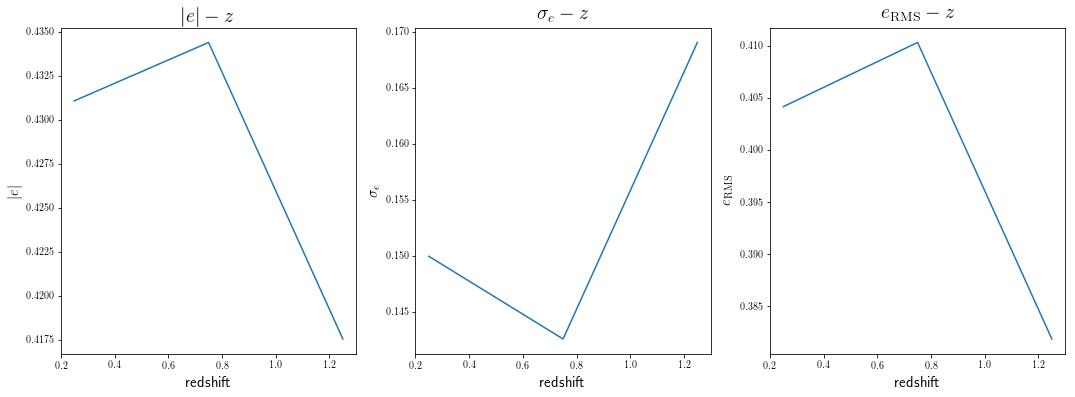

In [72]:
# Plot estimated sigma_e as a function of SNR, resolution.
fig = plt.figure(figsize=(18,6))
ax = fig.add_subplot(1,3,1)
ax.plot(mean_z,abs_e_sim)
ax.set_title(r'$|e|-z$',fontsize=20)
plt.xlabel('redshift',fontsize=15)
plt.ylabel(r'$|e|$',fontsize=15)

ax = fig.add_subplot(1,3,2)
ax.plot(mean_z,est_sigma_e)
ax.set_title(r'$\sigma_e-z$',fontsize=20)
plt.xlabel('redshift',fontsize=15)
plt.ylabel(r'$\sigma_e$',fontsize=15)

ax = fig.add_subplot(1,3,3)
ax.plot(mean_z,est_rms)
ax.set_title(r'$e_{\rm{RMS}}-z$',fontsize=20)
plt.xlabel('redshift',fontsize=15)
plt.ylabel(r'$e_{\rm{RMS}}$',fontsize=15)
#plt.savefig(os.path.join(pltDir,'sigmae_estimated.png'))

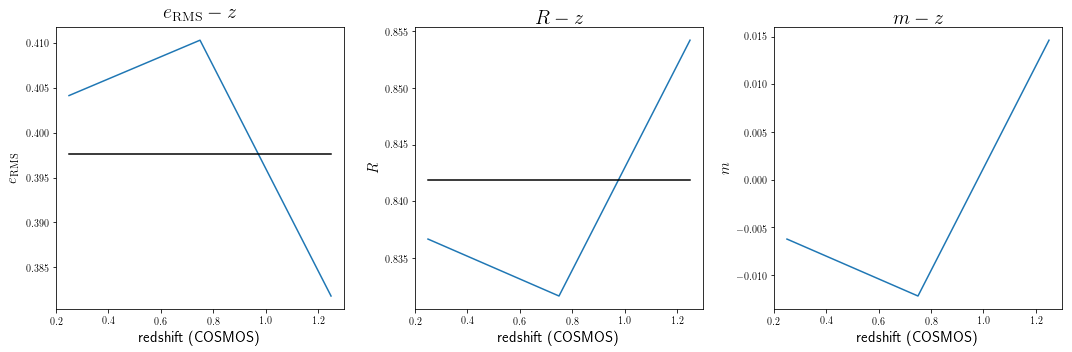

In [75]:
# Plot estimated sigma_e as a function of SNR, resolution.
fig = plt.figure(figsize=(15,5))
ax = fig.add_subplot(1,3,1)
ax.plot(mean_z,est_rms)
ax.plot(mean_z,[e_rms1]*3,c='black')
ax.set_title(r'$e_{\rm{RMS}}-z$',fontsize=20)
plt.xlabel('redshift (COSMOS)',fontsize=15)
plt.ylabel(r'$e_{\rm{RMS}}$',fontsize=15)
ax = fig.add_subplot(1,3,2)
ax.plot(mean_z,1-est_rms**2.)
ax.plot(mean_z,[1-e_rms1**2.]*3,c='black')
ax.set_title(r'$R-z$',fontsize=20)
plt.xlabel('redshift (COSMOS)',fontsize=15)
plt.ylabel(r'$R$',fontsize=15)
ax = fig.add_subplot(1,3,3)
ax.plot(mean_z,(1-est_rms**2.)/(1-e_rms1**2.)-1)
ax.set_title(r'$m-z$',fontsize=20)
plt.xlabel('redshift (COSMOS)',fontsize=15)
plt.ylabel(r'$m$',fontsize=15)
plt.tight_layout()
plt.savefig(os.path.join(pltDir,'intrinsicshape_vs_z-sim.eps'))

## Observation

In [57]:
if False:
    data=pyfits.getdata('../../database/smallcat-wl-s19-2-2.fits')
    # WL cut for Observation
    # cancel_shape_noise MUST be true for this test
    # since we are applying it to observation

    min_snr=10
    max_snr=200
    max_magA10=25.5
    min_res=0.3
    max_mag=24.5
    max_logb=-0.38
    max_sigma_e=0.4
    max_e=2.
    wlmask    =   utilities.galaxy_selector(catalog=data,
                    min_snr=min_snr, #snr
                    max_snr=max_snr,
                    max_magA10=max_magA10, #magA10
                    min_res=min_res, #res
                    max_mag=max_mag, #mag
                    max_logb=max_logb,#logb
                    force_90_pair=False,# orthogonal pairs
                    max_e=max_e,     #absE
                    max_sigma_e=max_sigma_e) #sigma_e
    # Use the sigma_e mdoel
    data=data[wlmask]
    pyfits.writeto('../../database/smalcat_wl-s19-reGausOptimize-redshift.fits',data)
else:
    data=pyfits.getdata('../../database/smalcat_wl-s19-reGausOptimize-redshift.fits')
    
# First: assemble the arrays for individual subfields into one big master catalog.
master_e1 = data['e1_regaus']
master_e2 = data['e2_regaus']
master_resolution = data['res']
master_snr = data['snr']
master_weight = data['weight']*utilities.get_weight_model(data)
master_model_sigma_e = utilities.get_sigma_e_model(data)
master_z=data['mizuki_photoz_best']

In [58]:
model_rms = np.zeros((nbin_z,nbin_1d, nbin_1d))
abs_e= np.zeros((nbin_z,nbin_1d, nbin_1d))
for k in range(nbin_z):
    for i in range(len(snr_lower)):
        for j in range(len(snr_lower)):
            in_bin = \
                (master_snr >= snr_lower[i]) & \
                (master_snr < snr_upper[i]) & \
                (master_resolution >= res_lower[i,j]) & \
                (master_resolution < res_upper[i,j]) &\
                (master_z>= z_lower[k])  &\
                (master_z< z_upper[k])
            model_rms[k,i,j] = np.sqrt(0.5*np.sum(
                    master_weight[in_bin]*\
                        (master_e1[in_bin]**2+master_e2[in_bin]**2-2*master_model_sigma_e[in_bin]**2)) / \
                                         np.sum(master_weight[in_bin]))
            abs_e[k,i,j] = np.sqrt(0.5*np.sum(
                    master_weight[in_bin]*(master_e1[in_bin]**2+master_e2[in_bin]**2))/np.sum(master_weight[in_bin]))

Text(0, 0.5, '$|e|$')

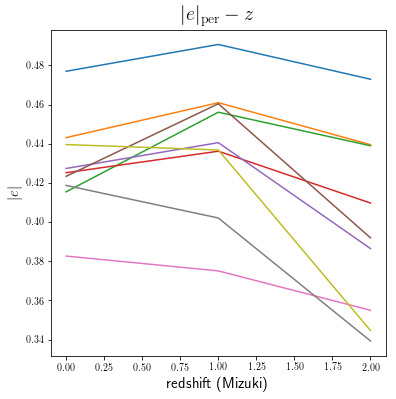

In [59]:
# Plot estimated sigma_e as a function of SNR, resolution.
fig = plt.figure(figsize=(6,6))
ax = fig.add_subplot(1,1,1)
for j in range(0,nbin_1d,1):
    for i in range(0,nbin_1d,1):
        ax.plot(abs_e[:,j,i])
ax.set_title(r'$|e|_{\rm{per}}-z$',fontsize=20)
plt.xlabel('redshift (Mizuki)',fontsize=15)
plt.ylabel(r'$|e|$',fontsize=15)

In [60]:
model_rms = np.zeros((nbin_z))
abs_e= np.zeros((nbin_z))
for k in range(nbin_z):
    in_bin = (master_z>= z_lower[k])  &\
        (master_z< z_upper[k])
    model_rms[k] = np.sqrt(0.5*np.sum(
            master_weight[in_bin]*\
                (master_e1[in_bin]**2+master_e2[in_bin]**2-2*master_model_sigma_e[in_bin]**2)) / \
                                 np.sum(master_weight[in_bin]))
    abs_e[k] = np.sqrt(0.5*np.sum(
            master_weight[in_bin]*(master_e1[in_bin]**2+master_e2[in_bin]**2))/np.sum(master_weight[in_bin]))
    
e_rms1 = np.sqrt(0.5*np.sum(master_weight*\
        (master_e1**2+master_e2**2-2*master_model_sigma_e**2)) / np.sum(master_weight))
e_rms2 = np.sqrt(np.sum(master_weight*(utilities.get_erms_model(data)**2)) / np.sum(master_weight))
out={'e_abs_per':abs_e,'model_rms':model_rms,'ave_rms':e_rms1}
np.save(os.path.join(pltDir,'intrinsicshape_vs_z-obs.npy'),out)

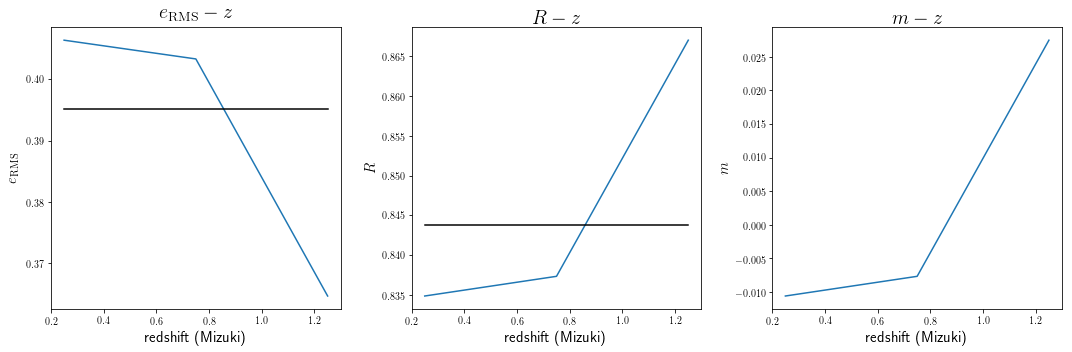

In [70]:
# Plot estimated sigma_e as a function of SNR, resolution.
fig = plt.figure(figsize=(15,5))
ax = fig.add_subplot(1,3,1)
ax.plot(mean_z,model_rms)
ax.plot(mean_z,[e_rms1]*3,c='black')
ax.set_title(r'$e_{\rm{RMS}}-z$',fontsize=20)
plt.xlabel('redshift (Mizuki)',fontsize=15)
plt.ylabel(r'$e_{\rm{RMS}}$',fontsize=15)
ax = fig.add_subplot(1,3,2)
ax.plot(mean_z,1-model_rms**2.)
ax.plot(mean_z,[1-e_rms1**2.]*3,c='black')
ax.set_title(r'$R-z$',fontsize=20)
plt.xlabel('redshift (Mizuki)',fontsize=15)
plt.ylabel(r'$R$',fontsize=15)
ax = fig.add_subplot(1,3,3)
ax.plot(mean_z,(1-model_rms**2.)/(1-e_rms1**2.)-1)
ax.set_title(r'$m-z$',fontsize=20)
plt.xlabel('redshift (Mizuki)',fontsize=15)
plt.ylabel(r'$m$',fontsize=15)
plt.tight_layout()
plt.savefig(os.path.join(pltDir,'intrinsicshape_vs_z-obs.eps'))

# S16A Calibration (Mandelbaum 2018)
There, deviations from equality that are of order 8 per cent were seen for photometric redshifts between 1–1.5 and S/N > 40, resulting in potential shear calibration biases of order 3 per cent at most
(assuming that the entirety of this 8 per cent deviation is due to misestimation of e rms and not σ e ). 

Using our canonical parent sample of galaxies (sample 4) we cannot directly disentangle the possible misestimates of e rms and σ e in this redshift range, because we center our cutouts at the locations of HSC detections down to the detection limit without good redshift estimates. Hence we revisit parent sample 2 to understand this eﬀect further. For that parent sample, we have high-quality 30-band photometric redshifts from COSMOS that can be used to reliably divide the sample based on redshift. 

Using those redshifts, we directly conﬁrm that at ﬁxed S/N and resolution factor, σ e has almost no dependence on redshift, while e rms depends on the joint distribution of redshift and S/N in a pattern consistent with what was seen in the real HSC data. The eﬀect is such that for a sample in the photo-z range [1, 1.5], there is a positive shear calibration bias of +3 per cent. Studies that divide the shear catalogue in ways that emphasize this redshift range, and that have a high level of statistical precision (such that a 3 per cent bias would be signiﬁcant), should correct for this.